In [145]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_shoppers_purchasing_intention_dataset = fetch_ucirepo(id=468)

# data (as pandas dataframes)
X = online_shoppers_purchasing_intention_dataset.data.features
y = online_shoppers_purchasing_intention_dataset.data.targets

# metadata
print(online_shoppers_purchasing_intention_dataset.metadata)

# variable information
print(online_shoppers_purchasing_intention_dataset.variables)


{'uci_id': 468, 'name': 'Online Shoppers Purchasing Intention Dataset', 'repository_url': 'https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/468/data.csv', 'abstract': 'Of the 12,330 sessions in the dataset,\n84.5% (10,422) were negative class samples that did not\nend with shopping, and the rest (1908) were positive class\nsamples ending with shopping.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 12330, 'num_features': 17, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Revenue'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2018, 'last_updated': 'Thu Jan 11 2024', 'dataset_doi': '10.24432/C5F88Q', 'creators': ['C. Sakar', 'Yomi Kastro'], 'intro_paper': {'ID': 367, 'type': 'NATIVE', 'title': 'Real-time prediction of online shoppers’ pur

In [146]:
X.duplicated().sum()

np.int64(125)

In [147]:
#Вывод - повторение логов для разных посещений допустимо

In [148]:
X.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


In [149]:
X.info()
X.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN


In [150]:
y.info()
y.describe(include="all")
y["Revenue"].sum()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Revenue  12330 non-null  bool 
dtypes: bool(1)
memory usage: 12.2 KB


np.int64(1908)

In [151]:
#вывод - нужно стратифицировать

In [152]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y["Revenue"],
)

In [153]:
from skrub import TableReport

report = TableReport(
    X_train,
    plot_distributions=True,
    compute_associations=True,
)

report.write_html("eda_report.html")
report.open()

Processing column  17 / 17


In [154]:
#Выводы:
# - У Duration распределение с хвостом - нужно логарифмировать
# - SpecialDay, OperatingSystems, Browser, Region, TrafficType, Weekend также экнодим, нет смысла в числовом распределении

In [155]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

extra_categorical_features = [
    "SpecialDay", "OperatingSystems", "Browser",
    "Region", "TrafficType", "Weekend",
]

log_features = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
]

numeric_features = [
    feature for feature in numeric_features
    if feature not in extra_categorical_features
    and feature not in log_features
]

categorical_features.extend(
    feature for feature in extra_categorical_features
    if feature not in categorical_features
)



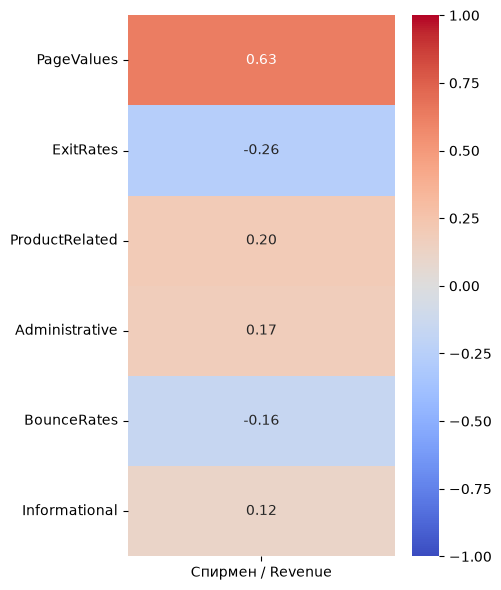

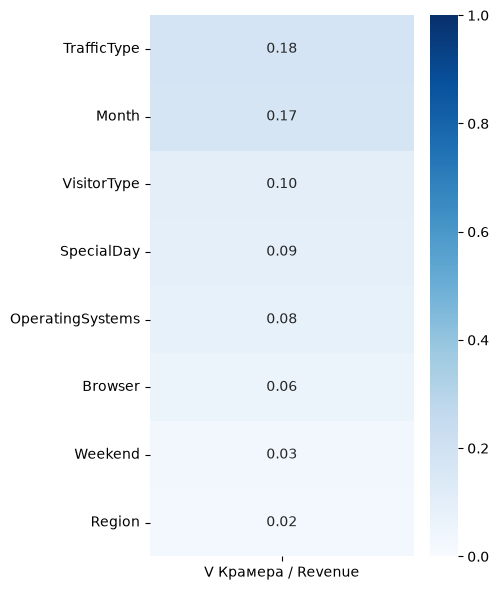

In [156]:
import pandas as pd
import seaborn as sb
from matplotlib import pyplot as plt
from scipy.stats.contingency import association

# Числовые признаки: корреляция Спирмена с Revenue.
correlations = X_train[numeric_features].corrwith(y_train["Revenue"], method="spearman")
correlations = correlations.sort_values(key=abs, ascending=False)

plt.figure(figsize=(5, 6))
sb.heatmap(
    correlations.to_frame("Спирмен / Revenue"),
    annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
)
plt.tight_layout()
plt.show()

# Категориальные признаки: V Крамера с Revenue.
cramer_correlations = {}
for feature in categorical_features:
    table = pd.crosstab(X_train[feature], y_train["Revenue"])
    cramer_correlations[feature] = association(table, method="cramer")

cramer_correlations = pd.Series(cramer_correlations).sort_values(ascending=False)

plt.figure(figsize=(5, 6))
sb.heatmap(
    cramer_correlations.to_frame("V Крамера / Revenue"),
    annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
)
plt.tight_layout()
plt.show()

In [157]:
#Нет ничего сильно подозрительного, но проверим корреляцию для значений PageValues

,count,sum,mean
PageValues,,,
PageValues = 0,7671,286,0.037283
PageValues > 0,2193,1240,0.565435


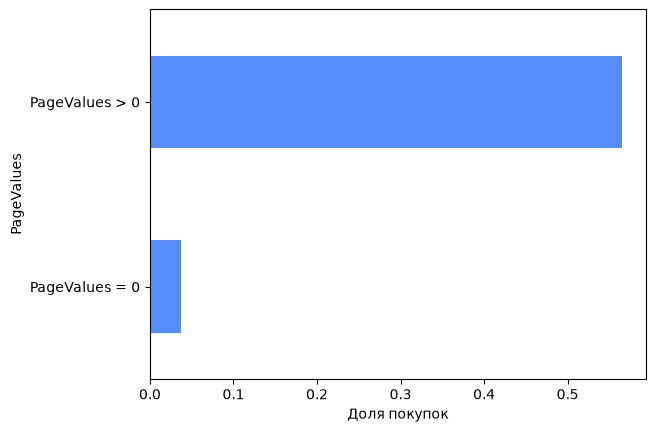

In [158]:
summary = (
    y_train["Revenue"]
    .groupby(X_train["PageValues"] > 0)
    .agg(["count", "sum", "mean"])
    .rename(index={False: "PageValues = 0", True: "PageValues > 0"})
)

display(summary)

summary["mean"].plot.barh(xlabel="Доля покупок")
plt.show()

In [159]:
#Можно добавить дополнительный признак для
# PageValues > 0 и = 0

X_train["HasPageValue"] = (X_train["PageValues"] > 0).astype(int)
X_test["HasPageValue"] = (X_test["PageValues"] > 0).astype(int)
numeric_features.append("HasPageValue")

In [160]:
import numpy as np
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([("scaler", StandardScaler())])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

log_pipeline = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("log_num", log_pipeline, log_features)
])

,Модель,PR-AUC,ROC-AUC,precision,recall,F1
0,"LogisticRegression(C=0.1, max_iter=1000)",0.701563,0.915425,0.709914,0.591082,0.645031
1,"LogisticRegression(C=0.1, l1_ratio=1, max_iter...",0.703651,0.914088,0.710898,0.589119,0.644244
2,"DecisionTreeClassifier(max_depth=5, min_sample...",0.683123,0.915542,0.694902,0.592383,0.638156


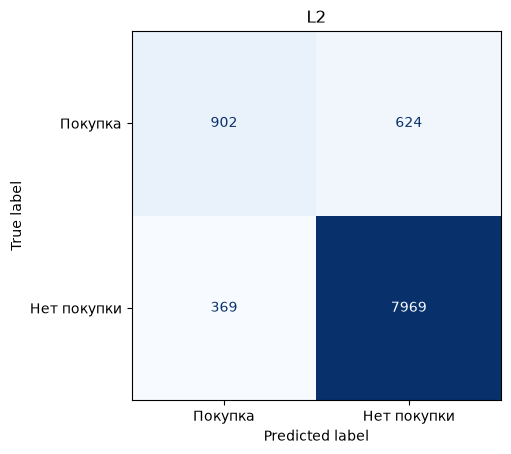

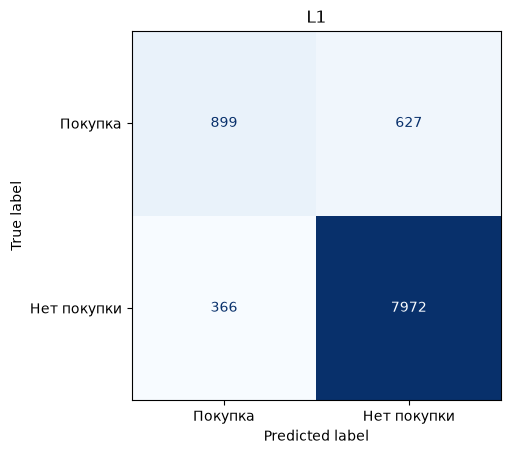

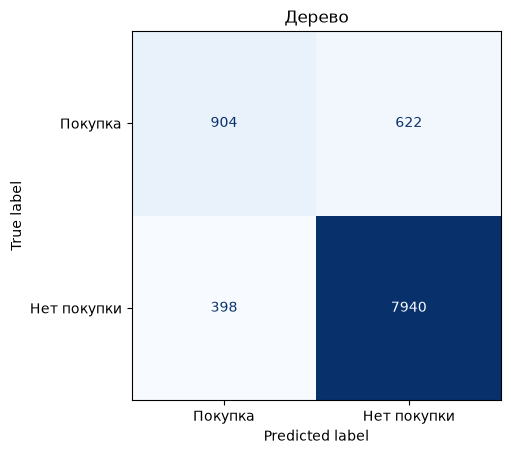

In [161]:
from sklearn.model_selection import ParameterGrid
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, auc, make_scorer, precision_recall_curve, precision_score
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from matplotlib import pyplot as plt

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)

scoring = {
    "PR-AUC": "average_precision",
    "ROC-AUC": "roc_auc",
    # Если нет предсказанных покупок, precision = 0 без предупреждения.
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "F1": "f1",
}

# Счётчики используют те же предсказания CV, что и precision/recall/F1.
def matrix_count(y_true, y_pred, position):
    return confusion_matrix(y_true, y_pred, labels=[True, False]).ravel()[position]

matrix_cells = ["TP", "FN", "FP", "TN"]
matrix_scoring = {
    name: make_scorer(matrix_count, position=position)
    for position, name in enumerate(matrix_cells)
}

results = []
best_models = []
confusion_matrices = []

for (model, params) in [
    (LogisticRegression(max_iter=1000), {"model__C": [0.01, 0.1, 1, 10, 100]}),
    (LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=1000), {"model__C": [0.01, 0.1, 1, 10]}),
    (DecisionTreeClassifier(random_state=0), {
            "model__max_depth": [None, 3, 5, 10],
            "model__min_samples_leaf": [1, 5, 10, 20],})
]:
    search = RandomizedSearchCV(
        estimator=Pipeline(
            [
                ("prep", preprocess),
                ("model", model),
            ]
        ),
        param_distributions=params,
        cv=cv,
        scoring=scoring | matrix_scoring,
        refit="PR-AUC",
        random_state = 0,
        n_iter=len(ParameterGrid(params)),
    ).fit(X_train, y_train["Revenue"])
    best_models.append(search.best_estimator_)


    #для вывода метрих лучших моделй в своем классе
    i = search.best_index_
    row = {
        "Модель": str(search.best_estimator_.named_steps["model"]),
    }
    for metric in scoring:
        row[metric] = search.cv_results_[f"mean_test_{metric}"][i]
    results.append(row)
    # Для матриц.Средние количества исходов умножаем на число фолдов и суммируем.
    matrix_counts = [search.cv_results_[f"mean_test_{cell}"][i] for cell in matrix_cells]
    confusion_matrices.append(
        np.rint(np.array(matrix_counts) * search.n_splits_).astype(int).reshape(2, 2)
    )

# Метрики лучших моделей каждого алгоритма
display(pd.DataFrame(results))

# Матрицы
for name, matrix in zip(["L2", "L1", "Дерево"], confusion_matrices):
    ConfusionMatrixDisplay(
        matrix, display_labels=["Покупка", "Нет покупки"]
    ).plot(cmap="Blues", colorbar=False)
    plt.title(name)
    plt.show()

recall и остальное тут рассчтывались при стандартном порогое 0.5, лучший порог еще не выяснили

Результаты до логарифмирования признаков
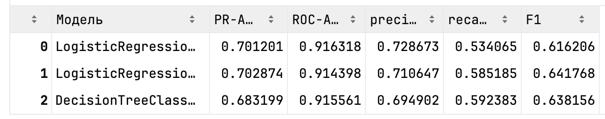

Почему максимизируем AP
Вот практическая польза хорошего ранжирования: при одинаковом количестве показов охватить больше будущих покупателей и сделать меньше ненужных показов.

AP оценивает качество такого отбора в целом при разном охвате. Если же заранее известно, что показов будет ровно 100, можно сравнивать модели непосредственно по результату среди первых 100 — например, по precision@100. Победитель по общему AP не обязательно окажется лучшим именно при таком лимите.

In [162]:
from sklearn.model_selection import ParameterGrid
# Те же модели и CV, но без PageValues и HasPageValue.
from sklearn.base import clone

excluded_features = ["PageValues", "HasPageValue"]
X_train_no_page = X_train.drop(columns=excluded_features)
X_test_no_page = X_test.drop(columns=excluded_features)

# Сохраняем обработку остальных признаков и удаляем исключённые столбцы из всех веток.
preprocess_no_page = clone(preprocess)
preprocess_no_page.transformers = [
    (name, transformer, [feature for feature in columns if feature not in excluded_features])
    for name, transformer, columns in preprocess_no_page.transformers
]

results_no_page = []
best_models_no_page = []

for model_no_page, params_no_page in [
    (LogisticRegression(max_iter=1000), {"model__C": [0.01, 0.1, 1, 10, 100]}),
    (LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=1000), {"model__C": [0.01, 0.1, 1, 10]}),
    (DecisionTreeClassifier(random_state=0), {
            "model__max_depth": [None, 3, 5, 10],
            "model__min_samples_leaf": [1, 5, 10, 20],})
]:
    search_no_page = RandomizedSearchCV(
        estimator=Pipeline([
            ("prep", preprocess_no_page),
            ("model", model_no_page),
        ]),
        param_distributions=params_no_page,
        cv=cv,
        scoring=scoring,
        refit="PR-AUC",
        random_state=0,
        n_iter=len(ParameterGrid(params_no_page)),
    ).fit(X_train_no_page, y_train["Revenue"])
    best_models_no_page.append(search_no_page.best_estimator_)

    i_no_page = search_no_page.best_index_
    row_no_page = {
        "Модель": str(search_no_page.best_estimator_.named_steps["model"]),
    }
    for metric in scoring:
        row_no_page[metric] = search_no_page.cv_results_[f"mean_test_{metric}"][i_no_page]
    results_no_page.append(row_no_page)

display(pd.DataFrame(results_no_page))

,Модель,PR-AUC,ROC-AUC,precision,recall,F1
0,"LogisticRegression(C=0.1, max_iter=1000)",0.335172,0.759000,0.439040,0.020310,0.038686
1,"LogisticRegression(C=0.1, l1_ratio=1, max_iter...",0.339100,0.757668,0.530303,0.013105,0.025558
2,"DecisionTreeClassifier(max_depth=5, min_sample...",0.315206,0.738324,0.492012,0.106806,0.172510


До логарифмирования признаков:
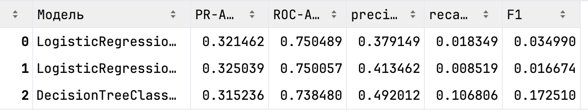
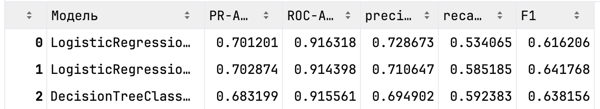

In [163]:
#Для подбора порога можно использовать TunedThresholdClassifierCV.

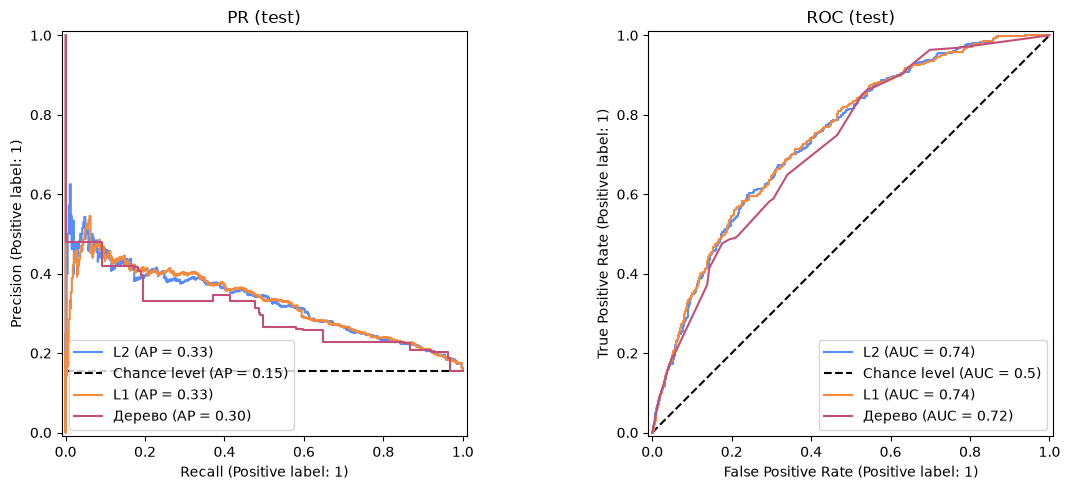

In [169]:
#Строим графики для лучших моделей
from matplotlib import pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
test_probabilities_no_page = {}

for name, model in zip(["L2", "L1", "Дерево"], best_models_no_page):
    probabilities = model.predict_proba(X_test_no_page)[:, 1]
    test_probabilities_no_page[name] = probabilities

    PrecisionRecallDisplay.from_predictions(
        y_test["Revenue"], probabilities, name=name, ax=axes[0],
        plot_chance_level=(name == "L2"),
    )
    RocCurveDisplay.from_predictions(
        y_test["Revenue"], probabilities, name=name, ax=axes[1],
        plot_chance_level=(name == "L2"),
    )

axes[0].set_title("PR (test)")
axes[1].set_title("ROC (test)")
plt.tight_layout()
plt.show()

In [173]:
from sklearn.metrics import get_scorer
from sklearn.model_selection import TunedThresholdClassifierCV

#Выбираем одну модель из троех предыдущих(лучших в своем классе) по средней AP из последнего поиска на train.
best_index_no_page = pd.DataFrame(results_no_page)["PR-AUC"].idxmax()
best_model_no_page = best_models_no_page[best_index_no_page]

#Подбираем порог по F1 на трёх фолдах внутри train.
tuned_best_model_no_page = TunedThresholdClassifierCV(
    estimator=best_model_no_page,
    scoring="f1",
    response_method="predict_proba",
    cv=cv,
    refit=True,
)
tuned_best_model_no_page.fit(X_train_no_page, y_train["Revenue"])

,"estimator estimator: estimator instanceThe classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...liblinear'))])
,"scoring scoring: str or callable, default=""balanced_accuracy""The objective metric to be optimized. Can be one of:- str: string associated to a scoring function for binary classification, see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.",'f1'
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke, for each classifier, `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'predict_proba'
,"cv cv: int, float, cross-validation generator, iterable or ""prefit"", default=NoneDetermines the cross-validation splitting strategy to train classifier.Possible inputs for cv are:* `None`, to use the default 5-fold stratified K-fold cross validation;* An integer number, to specify the number of folds in a stratified k-fold;* A float number, to specify a single shuffle split. The floating number should be in (0, 1) and represent the size of the validation set;* An object to be used as a cross-validation generator;* An iterable yielding train, test splits;* `""prefit""`, to bypass the cross-validation.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... warning:: Using `cv=""prefit""` and passing the same dataset for fitting `estimator` and tuning the cut-off point is subject to undesired overfitting. You can refer to :ref:`TunedThresholdClassifierCV_no_cv` for an example. This option should only be used when the set used to fit `estimator` is different from the one used to tune the cut-off point (by calling :meth:`TunedThresholdClassifierCV.fit`).",StratifiedKFo... shuffle=True)
,"thresholds thresholds: int or array-like, default=100The number of decision threshold to use when discretizing the output of theclassifier `method`. Pass an array-like to manually specify the thresholdsto use.",100
,"refit refit: bool, default=TrueWhether or not to refit the classifier on the entire training set oncethe decision threshold has been found.Note that forcing `refit=False` on cross-validation having morethan a single split will raise an error. Similarly, `refit=True` inconjunction with `cv=""prefit""` will raise an error.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. When `cv` represents across-validation strategy, the fitting and scoring on each data splitis done in parallel. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of cross-validation when `cv` is a float.See :term:`Glossary <random_state>`.",None
,"store_cv_results store_cv_results: bool, default=FalseWhether to store all scores and thresholds computed during the cross-validationprocess.",False
Name,Type,Value
"best_score_ best_score_: float or NoneThe optimal score of the objective metric, evaluated at `best_threshold_`.",float64,0.4063


In [174]:
#Лучшая моделдь на тест выборке
test_result_no_page = {
    "Модель": str(tuned_best_model_no_page.estimator_.named_steps["model"]),
    "Порог": tuned_best_model_no_page.best_threshold_,
}
for metric, scorer_name in scoring.items():
    scorer = get_scorer(scorer_name)
    test_result_no_page[metric] = scorer(
        tuned_best_model_no_page, X_test_no_page, y_test["Revenue"]
    )

display(pd.DataFrame([test_result_no_page]))

,Модель,Порог,PR-AUC,ROC-AUC,precision,recall,F1
0,"LogisticRegression(C=0.1, l1_ratio=1, max_iter...",0.204523,0.329051,0.742812,0.29172,0.599476,0.392459
